# Retail Sales Analysis

1. Data Source

The dataset used in this project contains retail shopping transaction data, including customer demographics, product categories, shopping malls, payment methods, quantities, prices, and sales amounts.

The analysis was performed using the dataset provided for this project.

2. Project Overview

The purpose of this project was to understand how a retail business was performing by analyzing its sales data. I explored which product categories and shopping malls generated the most sales, how customers purchased products, which payment methods they preferred, and how sales changed over time.

I also examined unusual price values to understand how outliers could affect the analysis.

3. Project Objectives

- Analyze overall sales performance.

- Identify the product categories generating the highest sales.

- Compare sales across shopping malls.

- Understand purchasing patterns by gender and age group.

- Compare sales and transaction counts across payment methods.

- Analyze monthly sales trends.

- Identify potential price outliers using the IQR method.

- Convert the analysis into practical business recommendations.

4. Tools and Technologies

Python: Used to perform the analysis.

Pandas: Used to load, clean, group, and summarize the data.

NumPy: Used for numerical operations.

Matplotlib: Used to customize charts and visualizations.

Seaborn: Used to create charts for comparing sales and exploring relationships.

Jupyter Notebook: Used to write code, analyze results, and document the project.

In [1]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("Data/customer_shopping_data.csv")

## EDA

In [3]:
df.head(10)

,invoice_no,customer_id,gender,age,category,quantity,price,payment_method,invoice_date,shopping_mall
0,I138884,C241288,Female,28,Clothing,5,1500.40,Credit Card,5/8/2022,Kanyon
1,I317333,C111565,Male,21,Shoes,3,1800.51,Debit Card,12/12/2021,Forum Istanbul
2,I127801,C266599,Male,20,Clothing,1,300.08,Cash,9/11/2021,Metrocity
3,I173702,C988172,Female,66,Shoes,5,3000.85,Credit Card,16/05/2021,Metropol AVM
4,I337046,C189076,Female,53,Books,4,60.60,Cash,24/10/2021,Kanyon
5,I227836,C657758,Female,28,Clothing,5,1500.40,Credit Card,24/05/2022,Forum Istanbul
6,I121056,C151197,Female,49,Cosmetics,1,40.66,Cash,13/03/2022,Istinye Park
7,I293112,C176086,Female,32,Clothing,2,600.16,Credit Card,13/01/2021,Mall of Istanbul
8,I293455,C159642,Male,69,Clothing,3,900.24,Credit Card,4/11/2021,Metrocity
9,I326945,C283361,Female,60,Clothing,2,600.16,Credit Card,22/08/2021,Kanyon


In [4]:
df.shape

(99457, 10)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99457 entries, 0 to 99456
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   invoice_no      99457 non-null  object 
 1   customer_id     99457 non-null  object 
 2   gender          99457 non-null  object 
 3   age             99457 non-null  int64  
 4   category        99457 non-null  object 
 5   quantity        99457 non-null  int64  
 6   price           99457 non-null  float64
 7   payment_method  99457 non-null  object 
 8   invoice_date    99457 non-null  object 
 9   shopping_mall   99457 non-null  object 
dtypes: float64(1), int64(2), object(7)
memory usage: 7.6+ MB


In [6]:
df.dtypes

invoice_no         object
customer_id        object
gender             object
age                 int64
category           object
quantity            int64
price             float64
payment_method     object
invoice_date       object
shopping_mall      object
dtype: object

In [7]:
df.isnull().sum()

invoice_no        0
customer_id       0
gender            0
age               0
category          0
quantity          0
price             0
payment_method    0
invoice_date      0
shopping_mall     0
dtype: int64

In [8]:
df.columns

Index(['invoice_no', 'customer_id', 'gender', 'age', 'category', 'quantity',
       'price', 'payment_method', 'invoice_date', 'shopping_mall'],
      dtype='object')

In [9]:
df["payment_method"].unique()

array(['Credit Card', 'Debit Card', 'Cash'], dtype=object)

In [10]:
df["shopping_mall"].unique()

array(['Kanyon', 'Forum Istanbul', 'Metrocity', 'Metropol AVM',
       'Istinye Park', 'Mall of Istanbul', 'Emaar Square Mall',
       'Cevahir AVM', 'Viaport Outlet', 'Zorlu Center'], dtype=object)

In [11]:
df.duplicated()

0        False
1        False
2        False
3        False
4        False
         ...  
99452    False
99453    False
99454    False
99455    False
99456    False
Length: 99457, dtype: bool

In [12]:
df[df.duplicated()]

,invoice_no,customer_id,gender,age,category,quantity,price,payment_method,invoice_date,shopping_mall


In [13]:
df.duplicated().sum()

np.int64(0)

In [14]:
df["invoice_date"].head()

0      5/8/2022
1    12/12/2021
2     9/11/2021
3    16/05/2021
4    24/10/2021
Name: invoice_date, dtype: object

In [15]:
df["invoice_date"].tail()

99452    21/09/2022
99453    22/09/2021
99454    28/03/2021
99455    16/03/2021
99456    15/10/2022
Name: invoice_date, dtype: object

In [16]:
df["invoice_date"] = pd.to_datetime(df["invoice_date"], dayfirst=True)

In [17]:
df.dtypes

invoice_no                object
customer_id               object
gender                    object
age                        int64
category                  object
quantity                   int64
price                    float64
payment_method            object
invoice_date      datetime64[ns]
shopping_mall             object
dtype: object

In [18]:
df.head()

,invoice_no,customer_id,gender,age,category,quantity,price,payment_method,invoice_date,shopping_mall
0,I138884,C241288,Female,28,Clothing,5,1500.40,Credit Card,2022-08-05,Kanyon
1,I317333,C111565,Male,21,Shoes,3,1800.51,Debit Card,2021-12-12,Forum Istanbul
2,I127801,C266599,Male,20,Clothing,1,300.08,Cash,2021-11-09,Metrocity
3,I173702,C988172,Female,66,Shoes,5,3000.85,Credit Card,2021-05-16,Metropol AVM
4,I337046,C189076,Female,53,Books,4,60.60,Cash,2021-10-24,Kanyon


In [19]:
df.describe()

,age,quantity,price,invoice_date
count,99457.000000,99457.000000,99457.000000,99457
mean,43.427089,3.003429,689.256321,2022-02-04 02:46:59.783424
min,18.000000,1.000000,5.230000,2021-01-01 00:00:00
25%,30.000000,2.000000,45.450000,2021-07-19 00:00:00
50%,43.000000,3.000000,203.300000,2022-02-05 00:00:00
75%,56.000000,4.000000,1200.320000,2022-08-22 00:00:00
max,69.000000,5.000000,5250.000000,2023-03-08 00:00:00
std,14.990054,1.413025,941.184567,NaN


The EDA concludes that there are no NULL values and Duplicates

## Univariate Analysis

Text(0.5, 1.0, 'Age Distribution')

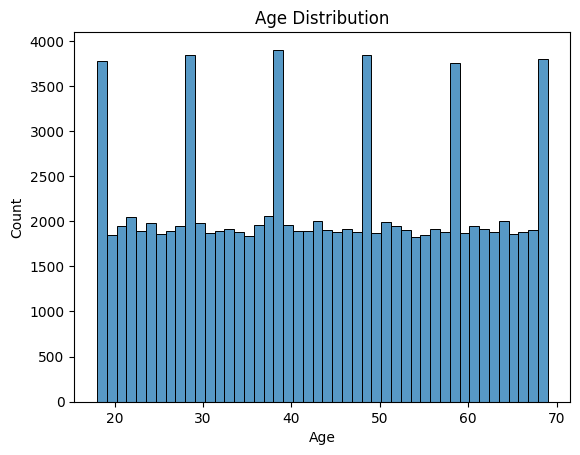

In [20]:
sns.histplot(df["age"])
plt.xlabel("Age")
plt.ylabel("Count")
plt.title("Age Distribution")

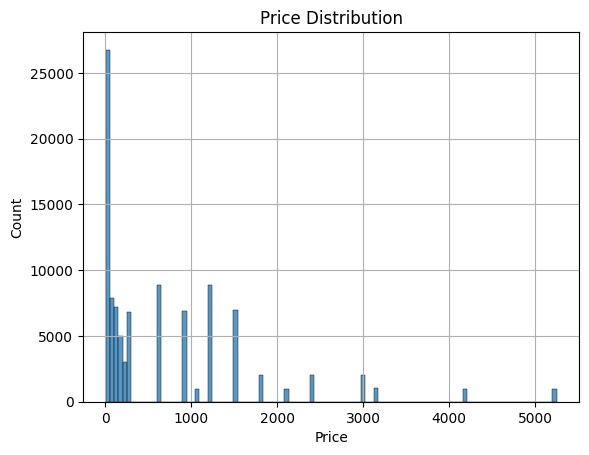

In [21]:
sns.histplot(df["price"])
plt.xlabel("Price")
plt.ylabel("Count")
plt.title("Price Distribution")
plt.grid()

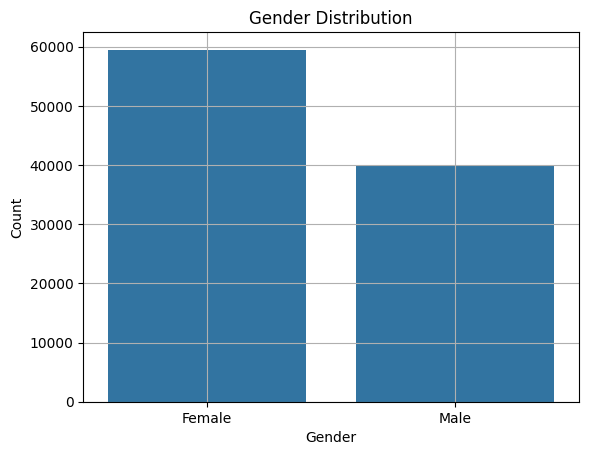

In [22]:
sns.countplot(x = df["gender"])
plt.xlabel("Gender")
plt.ylabel("Count")
plt.title("Gender Distribution")
plt.grid()

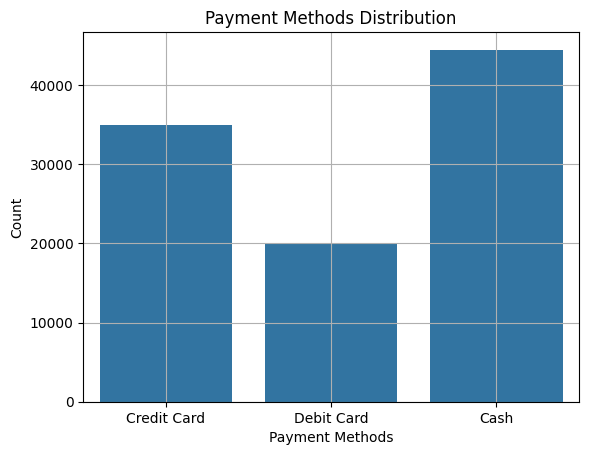

In [23]:
sns.countplot(x = df["payment_method"])
plt.xlabel("Payment Methods")
plt.ylabel("Count")
plt.title("Payment Methods Distribution")
plt.grid()

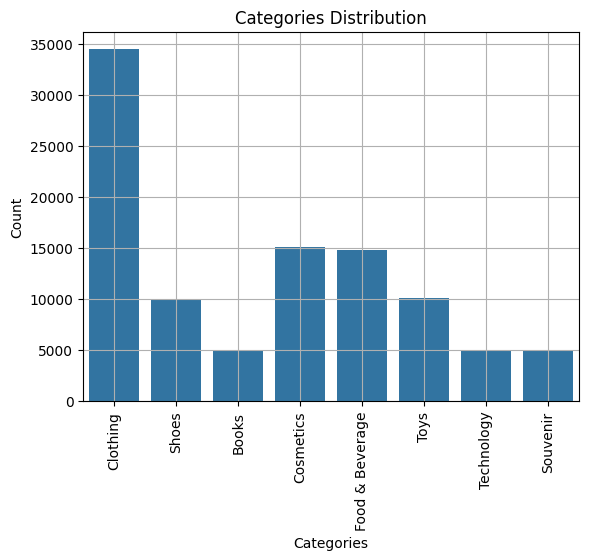

In [24]:
sns.countplot(x = df["category"])
plt.xlabel("Categories")
plt.xticks(rotation=90)
plt.ylabel("Count")
plt.title("Categories Distribution")
plt.grid()

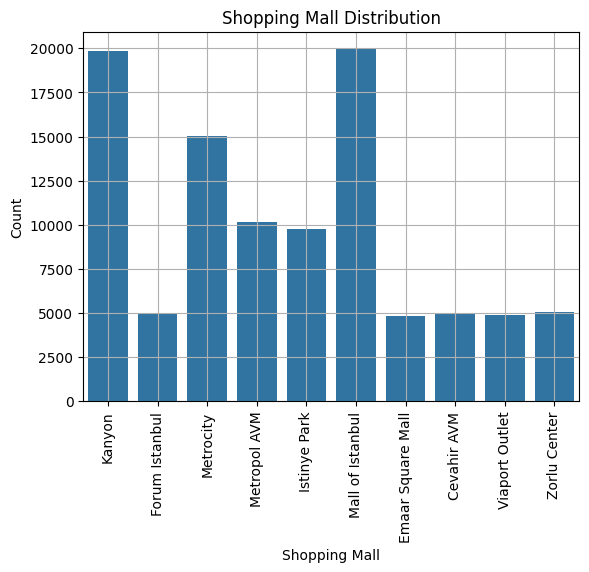

In [25]:
sns.countplot(x=df["shopping_mall"])
plt.xlabel("Shopping Mall")
plt.ylabel("Count")
plt.title("Shopping Mall Distribution")
plt.xticks(rotation=90)
plt.grid()

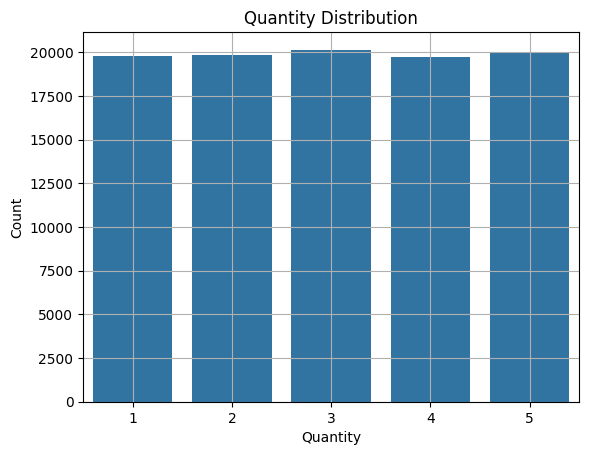

In [26]:
sns.countplot(x = df["quantity"])
plt.xlabel("Quantity")
plt.ylabel("Count")
plt.title("Quantity Distribution")
plt.grid()

## Bivariate Analysis

### Average Customers spend differs from Gender

In [27]:
price_mean = df.groupby("gender")["price"].mean()
price_mean

gender
Female    688.137615
Male      690.920933
Name: price, dtype: float64

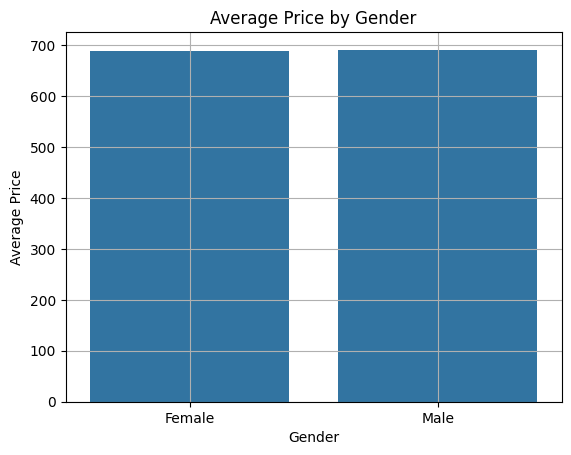

In [28]:
sns.barplot(x=price_mean.index, y=price_mean.values)
plt.xlabel("Gender")
plt.ylabel("Average Price")
plt.title("Average Price by Gender")
plt.grid()

### Average Transaction Price differ from Categories

In [29]:
categories_price_mean = df.groupby("category")["price"].mean()
categories_price_mean

category
Books                45.568621
Clothing            901.084021
Cosmetics           122.448626
Food & Beverage      15.671948
Shoes              1807.388568
Souvenir             34.894345
Technology         3156.935548
Toys                107.733185
Name: price, dtype: float64

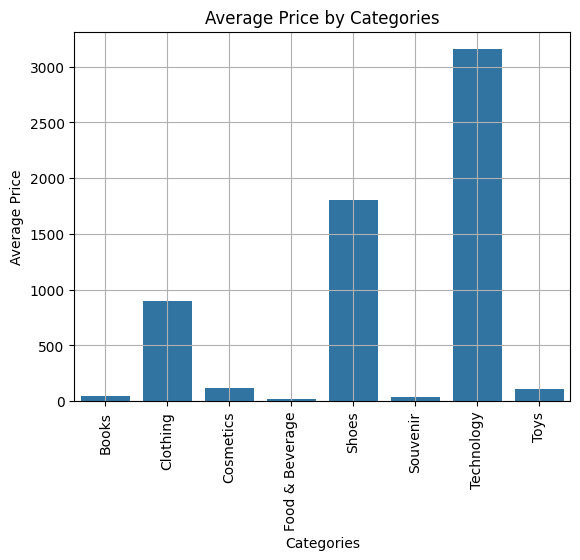

In [30]:
sns.barplot(x = categories_price_mean.index, y = categories_price_mean.values)
plt.xlabel("Categories")
plt.xticks(rotation=90)
plt.ylabel("Average Price")
plt.title("Average Price by Categories")
plt.grid()

### Average Transaction Price differ from PaymentMethod

In [31]:
payment_method_mean = df.groupby("payment_method")["price"].mean()
payment_method_mean

payment_method
Cash           690.823475
Credit Card    688.542467
Debit Card     687.029135
Name: price, dtype: float64

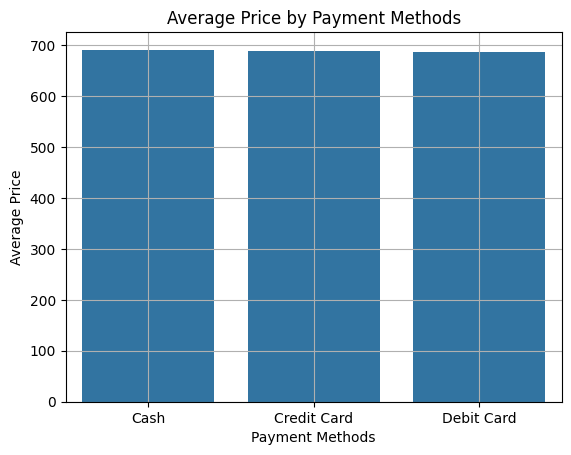

In [32]:
sns.barplot(x = payment_method_mean.index, y = payment_method_mean.values)
plt.xlabel("Payment Methods")
plt.ylabel("Average Price")
plt.title("Average Price by Payment Methods")
plt.grid()

### Quantity purchased with Price relationship

Text(0.5, 1.0, 'Price by Quantity')

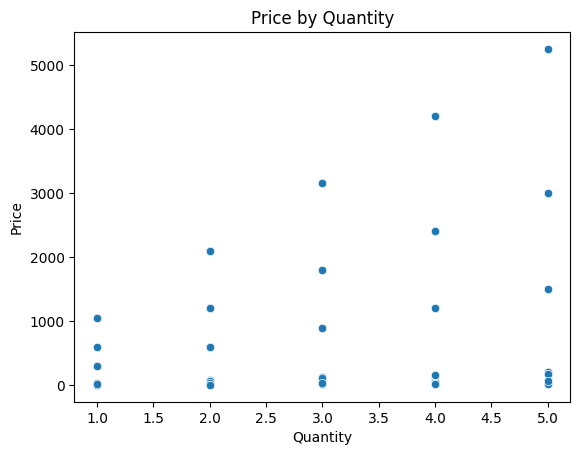

In [33]:
sns.scatterplot(x = df["quantity"], y = df["price"])
plt.xlabel("Quantity")
plt.ylabel("Price")
plt.title("Price by Quantity")

In [34]:
df["quantity"].corr(df["price"])

np.float64(0.3448798427911962)

### Checking for outliers 

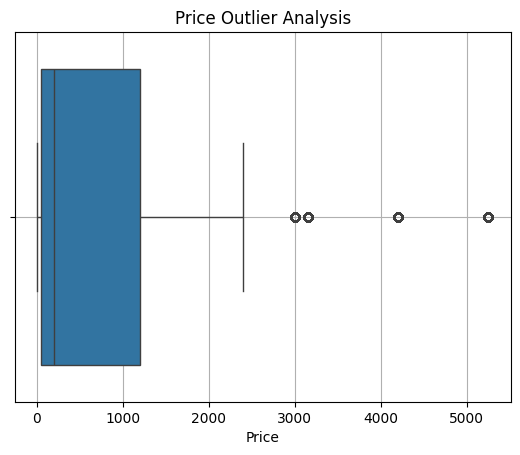

In [35]:
sns.boxplot(x = df["price"])
plt.xlabel("Price")
plt.title("Price Outlier Analysis")
plt.grid()

In [36]:
Minimum, Q1, Median, Q3, Maximum = np.quantile(df["price"], [0, 0.25, 0.50, 0.75, 1.0])

In [37]:
print(f" Minimum: {Minimum}\n Q1: {Q1}\n Median: {Median}\n Q3: {Q3}\n Maximum: {Maximum}")

 Minimum: 5.23
 Q1: 45.45
 Median: 203.3
 Q3: 1200.32
 Maximum: 5250.0


In [38]:
IQR = Q3 - Q1
IQR

np.float64(1154.87)

In [39]:
Lower_Limit = Q1 - 1.5 * IQR
Lower_Limit

np.float64(-1686.8549999999998)

In [40]:
Upper_Limit = Q3 + 1.5 * IQR
Upper_Limit

np.float64(2932.625)

In [41]:
# Count of Outlier
Outliers = df[df["price"]>Upper_Limit]
print("Number of Outliers:", len(Outliers))

Number of Outliers: 5024


In [42]:
# Percentage of outliers
Outlier_Percentage = (len(Outliers) / len(df) * 100)
print("Outlier Percentage:", Outlier_Percentage)

Outlier Percentage: 5.051429260886614


In [43]:
# Categories responsible for outliers
Outliers["category"].value_counts()

category
Technology    3011
Shoes         2013
Name: count, dtype: int64

IQR methods identify 5024 Outliers in Price, which is approximately 5.05% of the transactions. The categories responsible for these are Technology and Shoes. Show high price products

In [44]:
Outliers.groupby("category")["price"].agg(["count", "mean", "min", "max"])

,count,mean,min,max
category,,,,
Shoes,2013,3000.850000,3000.85,3000.85
Technology,3011,4197.210229,3150.00,5250.00


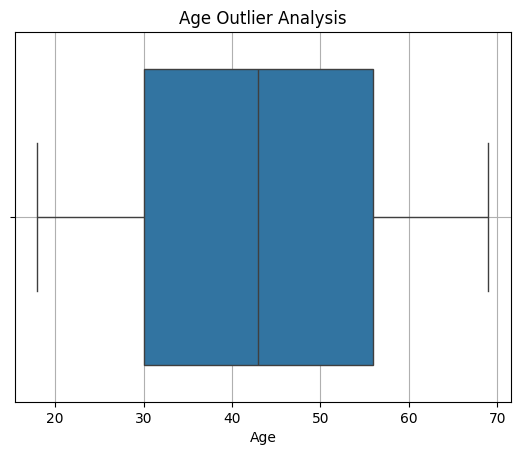

In [45]:
sns.boxplot(x = df["age"])
plt.xlabel("Age")
plt.title("Age Outlier Analysis")
plt.grid()

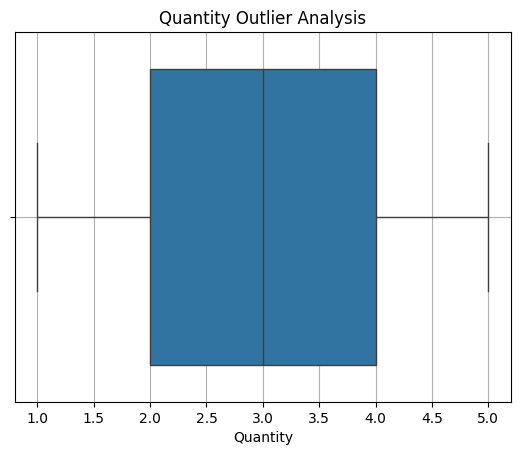

In [46]:
sns.boxplot(x = df["quantity"])
plt.xlabel("Quantity")
plt.title("Quantity Outlier Analysis")
plt.grid()

##  Business Analysis

### Total sales

In [47]:
df["Total_sales"] = df["quantity"] * df["price"]
Total_sales

NameError: name 'Total_sales' is not defined

In [48]:
df.head()

,invoice_no,customer_id,gender,age,category,quantity,price,payment_method,invoice_date,shopping_mall,Total_sales
0,I138884,C241288,Female,28,Clothing,5,1500.40,Credit Card,2022-08-05,Kanyon,7502.00
1,I317333,C111565,Male,21,Shoes,3,1800.51,Debit Card,2021-12-12,Forum Istanbul,5401.53
2,I127801,C266599,Male,20,Clothing,1,300.08,Cash,2021-11-09,Metrocity,300.08
3,I173702,C988172,Female,66,Shoes,5,3000.85,Credit Card,2021-05-16,Metropol AVM,15004.25
4,I337046,C189076,Female,53,Books,4,60.60,Cash,2021-10-24,Kanyon,242.40


In [71]:
df.columns.tolist()

['invoice_no',
 'customer_id',
 'gender',
 'age',
 'category',
 'quantity',
 'price',
 'payment_method',
 'invoice_date',
 'shopping_mall',
 'Total_sales']

In [60]:
df.shape

(99457, 51)

In [61]:
df.iloc[:, 10:].head()

,7502.0,5401.53,300.08,15004.25,242.4,40.66,1200.32,2700.72,20.92,15.15,...,4200.0,35.84,9450.0,896.0,600.17,1050.0,2400.68,187.68,11.73,Total_sales
0,7502.0,5401.53,300.08,15004.25,242.4,40.66,1200.32,2700.72,20.92,15.15,...,4200.0,35.84,9450.0,896.0,600.17,1050.0,2400.68,187.68,11.73,7502.00
1,7502.0,5401.53,300.08,15004.25,242.4,40.66,1200.32,2700.72,20.92,15.15,...,4200.0,35.84,9450.0,896.0,600.17,1050.0,2400.68,187.68,11.73,5401.53
2,7502.0,5401.53,300.08,15004.25,242.4,40.66,1200.32,2700.72,20.92,15.15,...,4200.0,35.84,9450.0,896.0,600.17,1050.0,2400.68,187.68,11.73,300.08
3,7502.0,5401.53,300.08,15004.25,242.4,40.66,1200.32,2700.72,20.92,15.15,...,4200.0,35.84,9450.0,896.0,600.17,1050.0,2400.68,187.68,11.73,15004.25
4,7502.0,5401.53,300.08,15004.25,242.4,40.66,1200.32,2700.72,20.92,15.15,...,4200.0,35.84,9450.0,896.0,600.17,1050.0,2400.68,187.68,11.73,242.40


In [62]:
df = df.iloc[:, [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, -1]]

In [64]:
df.shape

(99457, 11)

In [65]:
df.head()

,invoice_no,customer_id,gender,age,category,quantity,price,payment_method,invoice_date,shopping_mall,Total_sales
0,I138884,C241288,Female,28,Clothing,5,1500.40,Credit Card,2022-08-05,Kanyon,7502.00
1,I317333,C111565,Male,21,Shoes,3,1800.51,Debit Card,2021-12-12,Forum Istanbul,5401.53
2,I127801,C266599,Male,20,Clothing,1,300.08,Cash,2021-11-09,Metrocity,300.08
3,I173702,C988172,Female,66,Shoes,5,3000.85,Credit Card,2021-05-16,Metropol AVM,15004.25
4,I337046,C189076,Female,53,Books,4,60.60,Cash,2021-10-24,Kanyon,242.40


In [49]:
df["Total_sales"].sum()

np.float64(251505794.25000003)

In [50]:
df["invoice_no"].count()

np.int64(99457)

### Average Sales per Transaction

In [51]:
df["Total_sales"].mean()

np.float64(2528.78926822647)

### Category Analysis

In [52]:
df.groupby("category")["Total_sales"].sum()

category
Books              8.345529e+05
Clothing           1.139968e+08
Cosmetics          6.792863e+06
Food & Beverage    8.495351e+05
Shoes              6.655345e+07
Souvenir           6.358247e+05
Technology         5.786235e+07
Toys               3.980426e+06
Name: Total_sales, dtype: float64

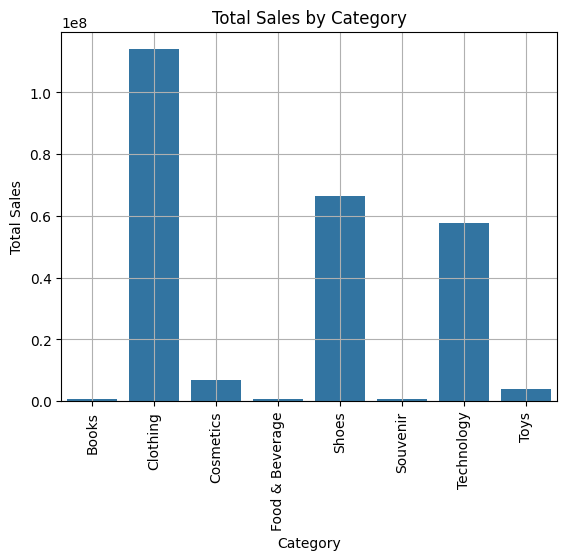

In [53]:
category_sales = df.groupby("category")["Total_sales"].sum()

sns.barplot(x = category_sales.index, y = category_sales.values)
plt.xlabel("Category")
plt.ylabel("Total Sales")
plt.title("Total Sales by Category")
plt.xticks(rotation=90)
plt.grid()

In [54]:
df.groupby("category")["quantity"].mean()

category
Books              3.007830
Clothing           3.002813
Cosmetics          3.011525
Food & Beverage    2.996548
Shoes              3.011461
Souvenir           2.974795
Technology         3.006605
Toys               3.005948
Name: quantity, dtype: float64

In [55]:
df.groupby("category")["invoice_no"].count()

category
Books               4981
Clothing           34487
Cosmetics          15097
Food & Beverage    14776
Shoes              10034
Souvenir            4999
Technology          4996
Toys               10087
Name: invoice_no, dtype: int64

In [56]:
category_sales_percentage = category_sales / df["Total_sales"].sum() * 100
category_sales_percentage

category
Books               0.331823
Clothing           45.325712
Cosmetics           2.700877
Food & Beverage     0.337780
Shoes              26.461995
Souvenir            0.252807
Technology         23.006369
Toys                1.582638
Name: Total_sales, dtype: float64

### Mall analysis

In [57]:
Mall_sales = df.groupby("shopping_mall")["Total_sales"].sum()
Mall_sales

shopping_mall
Cevahir AVM          12645138.20
Emaar Square Mall    12406100.29
Forum Istanbul       12303921.24
Istinye Park         24618827.68
Kanyon               50554231.10
Mall of Istanbul     50872481.68
Metrocity            37302787.33
Metropol AVM         25379913.19
Viaport Outlet       12521339.72
Zorlu Center         12901053.82
Name: Total_sales, dtype: float64

In [58]:
mall_transactions = df.groupby("shopping_mall")["invoice_no"].count()

mall_transactions

shopping_mall
Cevahir AVM           4991
Emaar Square Mall     4811
Forum Istanbul        4947
Istinye Park          9781
Kanyon               19823
Mall of Istanbul     19943
Metrocity            15011
Metropol AVM         10161
Viaport Outlet        4914
Zorlu Center          5075
Name: invoice_no, dtype: int64

In [59]:
mall_avg_sales = df.groupby("shopping_mall")["Total_sales"].mean()
mall_avg_sales

shopping_mall
Cevahir AVM          2533.588099
Emaar Square Mall    2578.694718
Forum Istanbul       2487.148017
Istinye Park         2517.005181
Kanyon               2550.281547
Mall of Istanbul     2550.894132
Metrocity            2485.030133
Metropol AVM         2497.777108
Viaport Outlet       2548.095181
Zorlu Center         2542.079570
Name: Total_sales, dtype: float64

### Payment Method analysis

In [60]:
payment_sales = df.groupby("payment_method")["Total_sales"].sum()

payment_sales

payment_method
Cash           1.128322e+08
Credit Card    8.807712e+07
Debit Card     5.059643e+07
Name: Total_sales, dtype: float64

In [61]:
payment_method_transactions = df.groupby("payment_method")["invoice_no"].count()
payment_method_transactions 

payment_method
Cash           44447
Credit Card    34931
Debit Card     20079
Name: invoice_no, dtype: int64

In [62]:
payment_method_avg_sales = df.groupby("payment_method")["Total_sales"].mean()

payment_method_avg_sales

payment_method
Cash           2538.579500
Credit Card    2521.460129
Debit Card     2519.867895
Name: Total_sales, dtype: float64

### Year

In [63]:
df["year"] = df["invoice_date"].dt.year
df["year"] 

0        2022
1        2021
2        2021
3        2021
4        2021
         ... 
99452    2022
99453    2021
99454    2021
99455    2021
99456    2022
Name: year, Length: 99457, dtype: int32

In [64]:
df["year"].unique()

array([2022, 2021, 2023], dtype=int32)

In [65]:
yearly_sales = df.groupby("year")["Total_sales"].sum()
yearly_sales

year
2021    1.145606e+08
2022    1.154368e+08
2023    2.150841e+07
Name: Total_sales, dtype: float64

In [66]:
df["month"] = df["invoice_date"].dt.month
df["month"] 

0         8
1        12
2        11
3         5
4        10
         ..
99452     9
99453     9
99454     3
99455     3
99456    10
Name: month, Length: 99457, dtype: int32

In [67]:
df["year_month"] = df["invoice_date"].dt.to_period("M")
df["year_month"]

0        2022-08
1        2021-12
2        2021-11
3        2021-05
4        2021-10
          ...   
99452    2022-09
99453    2021-09
99454    2021-03
99455    2021-03
99456    2022-10
Name: year_month, Length: 99457, dtype: period[M]

In [68]:
monthly_sales = df.groupby("year_month")["Total_sales"].sum()
monthly_sales

year_month
2021-01     9641614.62
2021-02     8772315.22
2021-03     9455359.38
2021-04     9389541.54
2021-05     9771756.97
2021-06     9286271.35
2021-07    10311119.68
2021-08     9630655.70
2021-09     9188165.62
2021-10    10263015.06
2021-11     9265555.29
2021-12     9585200.16
2022-01     9764311.14
2022-02     8344111.92
2022-03     9986685.16
2022-04     9326144.44
2022-05     9947574.13
2022-06     9647503.95
2022-07    10067602.95
2022-08     9651705.59
2022-09     9607629.29
2022-10    10282075.37
2022-11     8941584.66
2022-12     9869885.48
2023-01     9485599.83
2023-02     9508662.96
2023-03     2514146.79
Freq: M, Name: Total_sales, dtype: float64

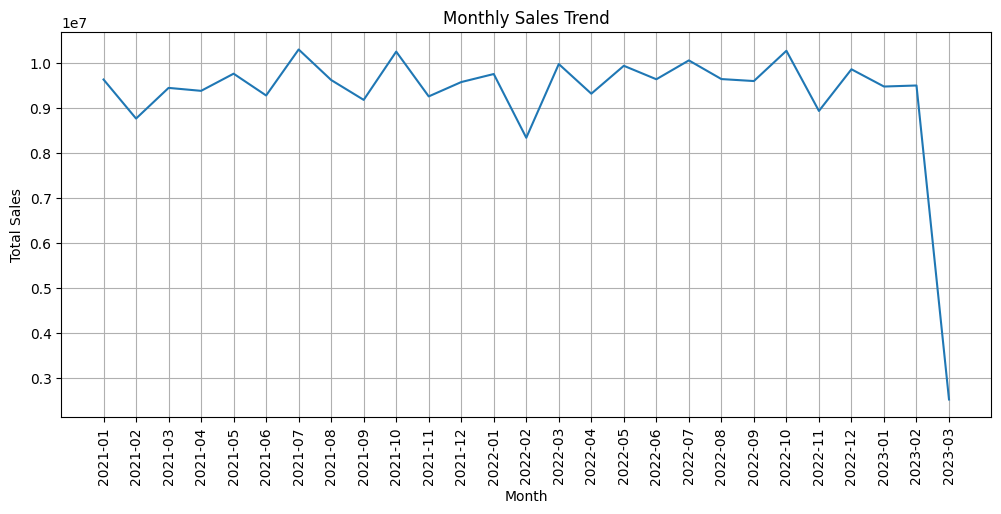

In [69]:
plt.figure(figsize=(12, 5))
sns.lineplot(x=monthly_sales.index.astype(str), y=monthly_sales.values)
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.title("Monthly Sales Trend")
plt.xticks(rotation=90)
plt.grid()


In [70]:
category_year_sales = df.groupby(["year", "category"])["Total_sales"].sum()
category_year_sales 

year  category       
2021  Books                369008.55
      Clothing           52604924.24
      Cosmetics           3033723.92
      Food & Beverage      390848.36
      Shoes              30125533.15
      Souvenir             288288.21
      Technology         25951800.00
      Toys                1796444.16
2022  Books                391945.65
      Clothing           51753897.36
      Cosmetics           3150499.44
      Food & Beverage      386852.64
      Shoes              30944765.20
      Souvenir             295865.79
      Technology         26651100.00
      Toys                1861888.00
2023  Books                 73598.70
      Clothing            9637969.44
      Cosmetics            608639.54
      Food & Beverage       71834.05
      Shoes               5483153.12
      Souvenir              51670.65
      Technology          5259450.00
      Toys                 322094.08
Name: Total_sales, dtype: float64

In [71]:
category_year_transactions = df.groupby(["year", "category"])["invoice_no"].count()
category_year_transactions


year  category       
2021  Books               2187
      Clothing           15973
      Cosmetics           6779
      Food & Beverage     6747
      Shoes               4594
      Souvenir            2270
      Technology          2257
      Toys                4575
2022  Books               2347
      Clothing           15560
      Cosmetics           6972
      Food & Beverage     6786
      Shoes               4591
      Souvenir            2301
      Technology          2316
      Toys                4678
2023  Books                447
      Clothing            2954
      Cosmetics           1346
      Food & Beverage     1243
      Shoes                849
      Souvenir             428
      Technology           423
      Toys                 834
Name: invoice_no, dtype: int64

In [72]:
category_avg_sales = df.groupby("category")["Total_sales"].mean()
category_avg_sales

category
Books                167.547260
Clothing            3305.500364
Cosmetics            449.947864
Food & Beverage       57.494251
Shoes               6632.793649
Souvenir             127.190368
Technology         11581.735388
Toys                 394.609521
Name: Total_sales, dtype: float64

### Gender Analysis 

In [74]:
gender_sales = df.groupby("gender")["Total_sales"].sum()
gender_sales

gender
Female    1.502071e+08
Male      1.012987e+08
Name: Total_sales, dtype: float64

In [75]:
gender_transactions = df.groupby("gender")["invoice_no"].count()
gender_transactions

gender
Female    59482
Male      39975
Name: invoice_no, dtype: int64

In [76]:
gender_avg_sales = df.groupby("gender")["Total_sales"].mean()
gender_avg_sales

gender
Female    2525.253623
Male      2534.050237
Name: Total_sales, dtype: float64

In [77]:
gender_category_transactions = df.groupby(["gender", "category"])["invoice_no"].count()
gender_category_transactions

gender  category       
Female  Books               2906
        Clothing           20652
        Cosmetics           9070
        Food & Beverage     8804
        Shoes               5967
        Souvenir            3017
        Technology          2981
        Toys                6085
Male    Books               2075
        Clothing           13835
        Cosmetics           6027
        Food & Beverage     5972
        Shoes               4067
        Souvenir            1982
        Technology          2015
        Toys                4002
Name: invoice_no, dtype: int64

In [78]:
gender_category_avg = df.groupby(["gender", "category"])["Total_sales"].mean()
gender_category_avg

gender  category       
Female  Books                168.380833
        Clothing            3304.846775
        Cosmetics            448.376245
        Food & Beverage       57.396933
        Shoes               6607.200821
        Souvenir             126.903281
        Technology         11630.308621
        Toys                 397.049479
Male    Books                166.379855
        Clothing            3306.475999
        Cosmetics            452.312985
        Food & Beverage       57.637718
        Shoes               6670.342801
        Souvenir             127.627371
        Technology         11509.875931
        Toys                 390.899590
Name: Total_sales, dtype: float64

In [80]:
gender_category_percentage = (
    gender_category_transactions
    / gender_category_transactions.groupby(level=0).sum()
    * 100
)

gender_category_percentage

gender  category       
Female  Books               4.885512
        Clothing           34.719747
        Cosmetics          15.248310
        Food & Beverage    14.801116
        Shoes              10.031606
        Souvenir            5.072123
        Technology          5.011600
        Toys               10.229986
Male    Books               5.190744
        Clothing           34.609131
        Cosmetics          15.076923
        Food & Beverage    14.939337
        Shoes              10.173859
        Souvenir            4.958099
        Technology          5.040650
        Toys               10.011257
Name: invoice_no, dtype: float64

### Customer-level analysis

In [81]:
df["customer_id"].nunique()

99457

In [82]:
customer_transaction_count = df["customer_id"].value_counts()
customer_transaction_count.value_counts()

count
1    99457
Name: count, dtype: int64

Age Analysis

In [83]:
bins = [17, 25, 35, 45, 55, 65, 69]

labels = ["18-25", "26-35", "36-45", "46-55", "56-65", "66-69"]

df["age_group"] = pd.cut(df["age"], bins=bins, labels=labels)

In [84]:
df[["age", "age_group"]].head(10)

,age,age_group
0,28,26-35
1,21,18-25
2,20,18-25
3,66,66-69
4,53,46-55
5,28,26-35
6,49,46-55
7,32,26-35
8,69,66-69
9,60,56-65


In [86]:
age_group_transactions = df.groupby("age_group", observed=True)["invoice_no"].count()
age_group_transactions

age_group
18-25    15359
26-35    19059
36-45    19436
46-55    19016
56-65    19016
66-69     7571
Name: invoice_no, dtype: int64

In [87]:
age_group_sales = df.groupby("age_group", observed=True)["Total_sales"].sum()
age_group_sales

age_group
18-25    38118271.35
26-35    47879659.58
36-45    50184235.79
46-55    48219742.64
56-65    47893010.77
66-69    19210874.12
Name: Total_sales, dtype: float64

In [88]:
age_group_avg_sales = df.groupby("age_group", observed=True)["Total_sales"].mean()
age_group_avg_sales

age_group
18-25    2481.819868
26-35    2512.181100
36-45    2582.024891
46-55    2535.745827
56-65    2518.563881
66-69    2537.428889
Name: Total_sales, dtype: float64

In [97]:
age_group_category = df.groupby(["age_group", "category"], observed=True)["invoice_no"].count()
age_group_category 

age_group  category       
18-25      Books               788
           Clothing           5337
           Cosmetics          2276
           Food & Beverage    2306
           Shoes              1550
           Souvenir            768
           Technology          751
           Toys               1583
26-35      Books               920
           Clothing           6614
           Cosmetics          2895
           Food & Beverage    2820
           Shoes              1928
           Souvenir            970
           Technology          962
           Toys               1950
36-45      Books               940
           Clothing           6711
           Cosmetics          2906
           Food & Beverage    2942
           Shoes              1926
           Souvenir            999
           Technology         1040
           Toys               1972
46-55      Books               981
           Clothing           6609
           Cosmetics          2962
           Food & Beverage  

In [101]:
age_group_category_percentage = (
    age_group_category 
    / age_group_category.groupby(level=0).sum()
    *100
)

age_group_category_percentage 

C:\Users\Aakanksha haravde\AppData\Local\Temp\ipykernel_22412\3750966834.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  / age_group_category.groupby(level=0).sum()


age_group  category       
18-25      Books               5.130542
           Clothing           34.748356
           Cosmetics          14.818673
           Food & Beverage    15.013998
           Shoes              10.091803
           Souvenir            5.000326
           Technology          4.889641
           Toys               10.306661
26-35      Books               4.827116
           Clothing           34.702765
           Cosmetics          15.189674
           Food & Beverage    14.796159
           Shoes              10.115956
           Souvenir            5.089459
           Technology          5.047484
           Toys               10.231387
36-45      Books               4.836386
           Clothing           34.528710
           Cosmetics          14.951636
           Food & Beverage    15.136859
           Shoes               9.909446
           Souvenir            5.139946
           Technology          5.350895
           Toys               10.146121
46-55      Bo

In [102]:
gender_age_sales = df.groupby(["gender", "age_group"], observed=True)["Total_sales"].sum()
gender_age_sales

gender  age_group
Female  18-25        23159143.70
        26-35        28292995.13
        36-45        30060801.14
        46-55        28566256.46
        56-65        29065794.75
        66-69        11062144.84
Male    18-25        14959127.65
        26-35        19586664.45
        36-45        20123434.65
        46-55        19653486.18
        56-65        18827216.02
        66-69         8148729.28
Name: Total_sales, dtype: float64

In [103]:
gender_age_avg_sales = df.groupby(["gender", "age_group"], observed=True)["Total_sales"].mean()
gender_age_avg_sales

gender  age_group
Female  18-25        2550.004812
        26-35        2479.666532
        36-45        2555.755921
        46-55        2520.403782
        56-65        2554.785510
        66-69        2449.002621
Male    18-25        2383.165151
        26-35        2560.683024
        36-45        2622.287549
        46-55        2558.381435
        56-65        2464.617885
        66-69        2668.215219
Name: Total_sales, dtype: float64

# Key Findings

1. Product categories: Clothing was the largest sales category, contributing approximately 45.33% of total sales. Shoes contributed 26.46%, followed by Technology at 23.01%.

2. Shopping malls: Mall of Istanbul generated the highest total sales at approximately 50.87 million, followed closely by Kanyon at 50.55 million.

3. Payment methods: Cash was the most frequently used payment method, with 44,447 transaction records and approximately 112.83 million in total sales.

4. Customer demographics: Female customers generated approximately 150.21 million in sales, compared with 101.30 million for male customers. However, the average sales amount per transaction was similar for both groups.

5. Age groups: Customers aged 36–45 generated the highest total sales, approximately 50.18 million, and had the highest average sales per transaction among the age groups analyzed.

6. Monthly trends: Monthly sales varied over time. October 2022 was the strongest month in the displayed results, with approximately 10.28 million in sales. The 2023 data covered only January to March.

7. Outlier analysis: The IQR method identified 5,024 potential price outliers. These were concentrated in the Shoes and Technology categories. The values were not automatically removed because unusually high prices may represent genuine transactions.

 Business Insights and Recommendations

1. Focus on the strongest product categories

Clothing, Shoes, and Technology together contributed approximately 94.8% of total sales. The business should monitor demand and stock availability in these categories while exploring opportunities to grow smaller categories.

2. Learn from high-performing shopping malls

Mall of Istanbul and Kanyon generated the highest sales. The business could compare their product mix, transaction counts, and customer preferences with other malls to identify practices worth adopting elsewhere.

3. Understand payment preferences

Cash generated the highest total sales and transaction count. The business should continue supporting customer payment preferences while maintaining convenient card payment options.

4. Tailor marketing to customer groups

Customers aged 36–45 generated the highest total sales and average sales per transaction. The business could investigate their preferred product categories and develop relevant promotions based on actual purchasing patterns.

5. Use monthly trends for planning

Monthly sales analysis can help the business plan inventory and promotions around stronger periods. Comparisons should use equivalent time periods, especially when analyzing incomplete years.

6. Investigate unusual prices carefully

Potential outliers should be checked before being removed. Keeping valid transactions helps prevent sales from being understated. The business should also distinguish sales revenue from accounting adjustments and returns where possible.